In [192]:
using CSV
using DataFrames
using ROC
using Plots
using LaTeXStrings

In [222]:
# For plots
base = 12
lfs = base # Legend font size
alfs = base # axis label font size
tfs = base # title font size
atfs = base # axis ticks font size
ga = 0.3 # grid alpha
sizes =(450,400) # standard size for single plots
rl = 0.065 # position of the "A" or "B" label in % 
ms = 6 # marker size
ls = 6 # line size
annfs = 34
#

34

In [196]:
# Set the data  directory to the parent directory of the script
wdir = dirname(@__DIR__)
cd(wdir)

In [218]:
include("src/score.jl")
include("src/misc.jl")

likelihood_null (generic function with 1 method)

In [317]:
variant="H3N2"
protein="HA"
year="2011"
directory_path = "data/$variant/$protein/results"
T0=observation_time(variant,protein,year)

24

In [268]:
pattern = r"simulation_results.*"
matching_files = filter(x -> occursin(pattern, x), readdir(directory_path))[1]
df_=DataFrame(CSV.File("$(directory_path)/$(matching_files)"));

In [318]:
# Initialize empty arrays to store AUC values
AUC_vs_f0 = []
AUC_vs_f0_null = []

# Set the frequency range and delta
delta = 0.05
frequencies = 0.1:0.1:0.9

# Iterate over different initial frequencies (f0)
for f0 in frequencies
    # Select trajectories with frequencies close to f0 at the endtime
    df_selected = df_[(f0 + delta) .> last.(parse_string.(df_.Frequency)) .>= (f0 - delta), :]

    # Filter trajectories based on observation time
    df_selected = df_selected[df_selected.Time .> T0, :]

    # Remove trajectories that remain polymorphic at the end of the future trajectory
    df_selected = df_selected[(df_selected.Fixation .== "lost") .| (df_selected.Fixation .== "fixed"), :]

    # Score simulations and null model based on selected trajectories
    scores_simulations = score_simulations(df_selected)
    scores_null_model = score_frequency(df_selected)

    # Calculate ROC curves for simulations and null model
    roc_simulations = ROC.roc(scores_simulations[:, 2], scores_simulations[:, 3], true)
    roc_null_model = ROC.roc(scores_null_model[:, 2], scores_null_model[:, 3], true)

    # Calculate AUC values and store in the respective arrays
    push!(AUC_vs_f0, AUC(roc_simulations))
    push!(AUC_vs_f0_null, AUC(roc_null_model))
end


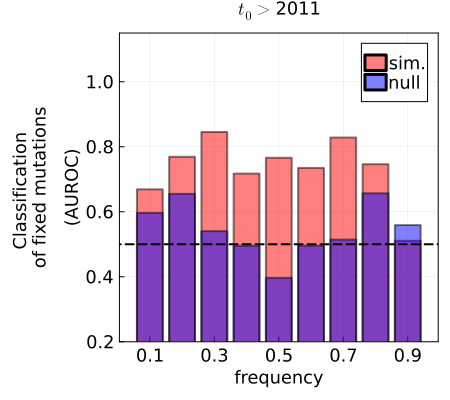

ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error
ERROR: syntax error


In [319]:
p=Plots.bar(frequencies,AUC_vs_f0,color=:red,alpha=0.5,line=2,label="sim.")
Plots.bar!(frequencies,AUC_vs_f0_null,color=:blue,alpha=0.5,line=2,legend=:topright,label="null")
Plots.plot!([0.5],linestyle=:dash,seriestype="hline",alpha=1.0,linewidth=2.0,marker=:false,color=:black,label="")

plot!(p,tickfontsize=tfs, legendfontsize=lfs, guidefontsize=alfs,titlefontsize=alfs)
plot!(p,title=L"t_0 > " * year,frame=:box,fmt=:svg,ylim=[0.2,1.15])
plot!(p, size=sizes)
xaxis!(p,0.1:0.2:1.0)
yaxis!(p,0.2:0.2:1.1)
#annotate!(p, 0.1, 1.0, text("A", annfs))

xlabel!("frequency")
ylabel!(latexstring("Classification \n of fixed mutations \n\n(AUROC)"))



In [259]:
1380*12

16560